In [1]:
import numpy,pandas,json,sys
from matplotlib import pyplot
import matplotlib.patches as patches

from geochemistry_helpers import Sampling,GaussianProcess

sys.path.append("../../code/utility")
from load_data import load_cadmium,split_data_by_site,load_carbon

# Set default dpi for saving
pyplot.rcParams['savefig.dpi'] = 600

In [2]:
# Load in data
## Data
data_directory = "../../data/"
d114cd_data = load_cadmium(data_directory)
svalbard_cd_data,arctic_cd_data,northsea_cd_data,kheu_cd_data = split_data_by_site(d114cd_data)

d13c_data = load_carbon(data_directory)
svalbard_c_data,arctic_c_data,northsea_c_data,kheu_c_data = split_data_by_site(d13c_data)

# Collate the ages
ages = d114cd_data["Age model"].values

# Load in GP
d114cd_gp = GaussianProcess().fromJSON(data_directory+"/output/d114cd_gp.json")
d13C_gp = GaussianProcess().fromJSON(data_directory+"/output/d13c_gp.json")

# Load in prior_results
with open(data_directory+"/output/invert_organic_prior_results.json","r") as file:
    prior_results = json.load(file)
# Load in posterior_results
with open(data_directory+"/output/invert_organic_posterior_results.json","r") as file:
    posterior_results = json.load(file)

# Load in metrics
prior_metrics = pandas.read_excel(data_directory+"/output/invert_organic_prior_metrics.xlsx")
posterior_metrics = pandas.read_excel(data_directory+"/output/invert_organic_posterior_metrics.xlsx")

## Empirical onset calculation
start_index = 429
end_index = 456
onset_time = (d13c_data["Age model"].loc[start_index] - d13c_data["Age model"].loc[end_index])*1e6  # in years
adjustment_center = (d13c_data["Age model"].loc[start_index] + d13c_data["Age model"].loc[end_index])/2
onset_adjustment = (onset_time-5e3)/1e6 * 1.4  # compress to make onset 5 kyr duration
steepness = 120

def compress_leftward(ages, focal_age, steepness=0.1, scale=10.0):
    """
    Compresses ages increasingly to the left of focal_age using a flipped sigmoid transform.

    Parameters:
        ages (np.array): Original age values
        focal_age (float): Age where compression is strongest
        steepness (float): Controls sharpness of transition
        scale (float): Maximum adjustment (positive = compress)

    Returns:
        np.array: Adjusted ages
    """
    sigmoid = 1 / (1 + numpy.exp(steepness * (ages - focal_age)))
    return ages - scale * sigmoid

# Adjust ages to compress rightward towards 55.68 Ma
adjusted_data_ages = compress_leftward(ages, focal_age=55.86, steepness=steepness, scale=-onset_adjustment)
adjusted_smooth_ages = compress_leftward(prior_metrics["time"].values[0:-1], focal_age=adjustment_center, steepness=steepness, scale=-onset_adjustment)
adjusted_d13c_ages = compress_leftward(d13c_data["Age model"], focal_age=adjustment_center, steepness=steepness, scale=-onset_adjustment)
adjusted_d13c_smooth_ages = compress_leftward(prior_metrics["time"].values, focal_age=adjustment_center, steepness=steepness, scale=-onset_adjustment)


timestep = prior_metrics["time"].values[0]-prior_metrics["time"].values[1]

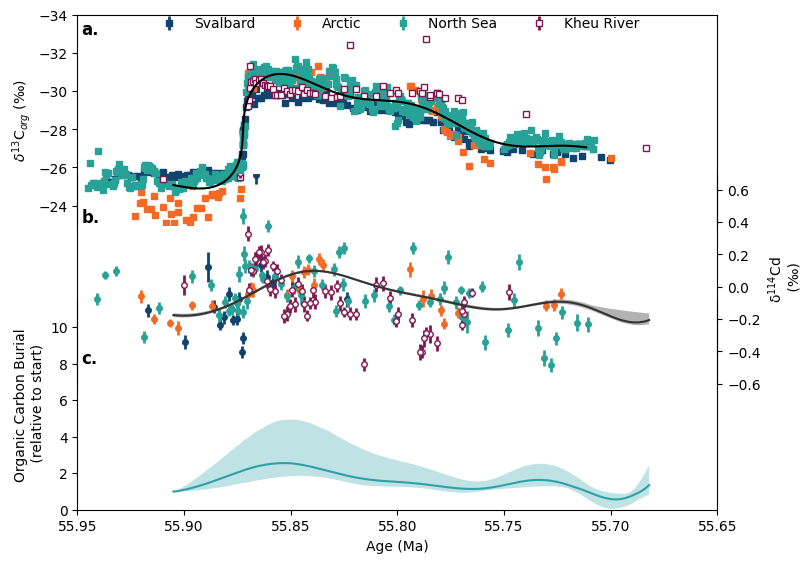

In [3]:
# Plot
figure,axes = pyplot.subplots(nrows=3,figsize=(8,6))
common_attributes = {"fmt":'s',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}

svalbard_c_adjusted_ages = compress_leftward(svalbard_c_data["Age model"], focal_age=adjustment_center, steepness=steepness, scale=-onset_adjustment)
arctic_c_adjusted_ages = compress_leftward(arctic_c_data["Age model"], focal_age=adjustment_center, steepness=steepness, scale=-onset_adjustment)
northsea_c_adjusted_ages = compress_leftward(northsea_c_data["Age model"], focal_age=adjustment_center, steepness=steepness, scale=-onset_adjustment)
kheu_c_adjusted_ages = compress_leftward(kheu_c_data["Age model"], focal_age=adjustment_center, steepness=steepness, scale=-onset_adjustment)

handle_0 = axes[0].errorbar(svalbard_c_adjusted_ages,svalbard_c_data["δ13Corg(‰)"],yerr=0.1,color="#12436D",ecolor="#12436D",**common_attributes)
handle_1 = axes[0].errorbar(arctic_c_adjusted_ages,arctic_c_data["δ13Corg(‰)"],yerr=0.1,color="#F46A25",ecolor="#F46A25",**common_attributes)
handle_2 = axes[0].errorbar(northsea_c_adjusted_ages,northsea_c_data["δ13Corg(‰)"],yerr=0.1,color="#28A197",ecolor="#28A197",**common_attributes)
handle_3 = axes[0].errorbar(kheu_c_adjusted_ages,kheu_c_data["δ13Corg(‰)"],yerr=0.1,markeredgecolor="#801650",ecolor="#801650",fmt='s',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

d13c_gp_query_locations_adjusted = compress_leftward(d13C_gp.query_locations[-1], focal_age=adjustment_center, steepness=steepness, scale=-onset_adjustment)
axes[0].plot(d13c_gp_query_locations_adjusted,d13C_gp.means[-1][0:],color="black",linestyle="-",zorder=5)

d13C_patch_y = numpy.concatenate((numpy.squeeze(d13C_gp.quantile(0.025,group=-1))[0:],
                                      numpy.squeeze(d13C_gp.quantile(0.975,group=-1))[::-1]))
d13C_patch_x = numpy.concatenate((d13c_gp_query_locations_adjusted,
                                      d13c_gp_query_locations_adjusted[::-1]))
d13C_patch = patches.Polygon(numpy.concatenate((d13C_patch_x[:,numpy.newaxis],
                                                d13C_patch_y[:,numpy.newaxis]),
                                               axis=1),facecolor="grey",alpha=0.5,zorder=4)
axes[0].add_patch(d13C_patch)

# d13C_gp.plotMean(group=-1,color="black",axis=axes[0])
# d13C_gp.plotArea(group=-1,color="black",alpha=0.5,set_axes=False,axis=axes[0])

axes[0].set_ylabel("$\\delta^{13}$C$_{org}$ (‰)")
axes[0].set_ylim((-23,-34))

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"],ncols=4,loc="upper center",bbox_to_anchor=(0,0.05,1,1),frameon=False)

common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}

svalbard_adjusted_ages = compress_leftward(svalbard_cd_data["Age model"], focal_age=adjustment_center, steepness=steepness, scale=-onset_adjustment)
arctic_adjusted_ages = compress_leftward(arctic_cd_data["Age model"], focal_age=adjustment_center, steepness=steepness, scale=-onset_adjustment)
northsea_adjusted_ages = compress_leftward(northsea_cd_data["Age model"], focal_age=adjustment_center, steepness=steepness, scale=-onset_adjustment)
kheu_adjusted_ages = compress_leftward(kheu_cd_data["Age model"], focal_age=adjustment_center, steepness=steepness, scale=-onset_adjustment)

handle_0 = axes[1].errorbar(svalbard_adjusted_ages,svalbard_cd_data["δ114Cd(‰)"],yerr=svalbard_cd_data["δ114Cd (2σ)"],color="#12436D",ecolor="#12436D",**common_attributes)
handle_1 = axes[1].errorbar(arctic_adjusted_ages,arctic_cd_data["δ114Cd(‰)"],yerr=arctic_cd_data["δ114Cd (2σ)"],color="#F46A25",ecolor="#F46A25",**common_attributes)
handle_2 = axes[1].errorbar(northsea_adjusted_ages,northsea_cd_data["δ114Cd(‰)"],yerr=northsea_cd_data["δ114Cd (2σ)"],color="#28A197",ecolor="#28A197",**common_attributes)
handle_3 = axes[1].errorbar(kheu_adjusted_ages,kheu_cd_data["δ114Cd(‰)"],yerr=kheu_cd_data["δ114Cd (2σ)"],markeredgecolor="#801650",ecolor="#801650",fmt='o',markerfacecolor="#ffffff",zorder=0,markersize=4,linewidth=2)

indices = range(0,len(prior_results))
colormap = pyplot.colormaps.get_cmap("autumn")(numpy.linspace(0,1,len(indices)))


time = prior_metrics["time"].values[0:-1]
interpolation_ages = [ages,time]

# First subplot
d114Cd_prior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
d114Cd_prior_patch_y = numpy.concatenate((numpy.array(prior_metrics["seawater_d114Cd_lower_quantile"][0:-1]),
                                    numpy.array(prior_metrics["seawater_d114Cd_upper_quantile"][0:-1][::-1])))

d114Cd_prior_patch = patches.Polygon(numpy.concatenate((d114Cd_prior_patch_x[:,numpy.newaxis],d114Cd_prior_patch_y[:,numpy.newaxis]),axis=1),facecolor="#666666",alpha=0.5)
axes[1].add_patch(d114Cd_prior_patch)
axes[1].plot(time,posterior_metrics["seawater_d114Cd_median"][0:-1],color="#333333",linestyle="-")

axes[1].set_ylim((-0.6,0.7))
axes[1].set_ylabel("δ$^{114}$Cd\n (‰)")


organic_posterior_patch_x = numpy.concatenate((numpy.array(time),numpy.array(time[::-1]))) 
organic_posterior_patch_y = numpy.concatenate((numpy.array(posterior_metrics["relative_organic_flux_lower_quantile"][0:-1]),
                                    numpy.array(posterior_metrics["relative_organic_flux_upper_quantile"][0:-1][::-1])))

organic_posterior_patch = patches.Polygon(numpy.concatenate((organic_posterior_patch_x[:,numpy.newaxis],
                                                                    organic_posterior_patch_y[:,numpy.newaxis]),
                                                                    axis=1),
                                                         facecolor="#2ea0a8",
                                                         alpha=0.3)
axes[2].add_patch(organic_posterior_patch)
axes[2].plot(time,posterior_metrics["relative_organic_flux_median"][0:-1],color="#2ea0a8",linestyle="-")

axes[2].set_ylim((0.0,11.5))
axes[2].set_ylabel("Organic Carbon Burial\n (relative to start)")
axes[2].set_xlabel("Age (Ma)")

# Move the axes to overlap
axes_height = 0.35
axes_width = 0.8
axes[0].set_position([0.125,0.575,axes_width,axes_height])
axes[1].set_position([0.125,0.31,axes_width,axes_height])
axes[2].set_position([0.125,0.1,axes_width,axes_height])

# Move middle y axis to right
axes[1].yaxis.tick_right()
axes[1].yaxis.set_label_position("right")

for axis in axes:
    axis.set_facecolor("none")
    axis.spines['top'].set_visible(False)
    axis.spines['bottom'].set_visible(False)
    axis.set_xlim((55.95,55.65))
for axis in axes[:-1]:
    axis.get_xaxis().set_ticks([])
axes[0].spines['top'].set_visible(True)
axes[-1].spines['bottom'].set_visible(True)

# Add alphabetical labels
label_x = 55.948
axes[0].text(label_x,-33,"a.",fontsize=12,fontweight="bold")
axes[1].text(label_x,0.4,"b.",fontsize=12,fontweight="bold")
axes[2].text(label_x,8.0,"c.",fontsize=12,fontweight="bold")

# figure.savefig("./figures/carbon_cadmium_burial.pdf",transparent=True)
figure.savefig("../../figures/carbon_cadmium_burial_relative.png",dpi=600)

pyplot.show()